# Which inputs the solar model keeps

The plan's model is LightGBM giving a low, a middle and a high forecast per slot. [Notebook 10](10_what_the_forecast_knows.ipynb) set its bar: the seven-day mean scaled by the forecast misses by 6.06% of capacity on daylight slots. This notebook asks one question: **given everything the plan lists as an input, which inputs does the model keep?** Two smaller questions have to be answered on the way, because the comparison rests on them: does a training repeat exactly, and does this notebook score a forecast the way the pipeline does?

Written down before it was run:

| We assumed | What would make us think again |
| --- | --- |
| A training repeats exactly on one machine, so two sets of inputs differ only by their inputs | If it doesn't, forecasts are rounded before they are fingerprinted, and differences between sets are read against the spread between repeats |
| The model given every input beats the scaled seven-day mean | If it doesn't, the plan's fifth done-when item is not met with plain settings |
| An input's worth is read by leaving it out | – |
| The range between the low and the high holds somewhat under the 80% it is meant to | Reported, not corrected: correcting it is tuning, which phase 1 leaves out |

The model is `train_boosted` in `jtf/ml/models.py`, with LightGBM's default settings, and the months are trained by `train_by_month` in `jtf/ml/replay.py`: the code a recorded run uses. Nothing about the model is defined in this notebook except, in section 5, a second target tried once.

Every choice here is made on the 16 test months from March 2025 to June 2026. July to October 2026 are held back and not read.

## 0. Setup

**Step.** The rows are read as a run reads them: `BacktestWarehouse.training` gives every labelled slot up to 30 June 2026 with the features as DWS knew them at the slot's decision time (09:00 the day before), the label, and whether the slot is in daylight. `ads_ml_day_solar` adds how each day turned out (its sky, whether it was curtailed, its season), for reading results only.

The eleven candidates are the plan's list of inputs. Power is given as a share of capacity:

| Input | What it is |
| --- | --- |
| `mean_7d_share`, `d2_share` | The same slot's output: its mean over the last seven complete days, and two days back |
| `clear_sky_share` | Clear-sky output for the slot |
| `forecast_ghi_w_m2`, `forecast_direct_w_m2`, `forecast_diffuse_w_m2` | The forecast's radiation for the slot: total, direct and diffuse |
| `forecast_cloud_cover_pct`, `forecast_temperature_c` | The forecast's cloud cover and temperature |
| `forecast_ghi_mean_7d_w_m2` | The forecast's total radiation for the same slot, averaged over the last seven days |
| `half_hour`, `day_of_year` | Read off the slot itself, in JST |

In [1]:
import hashlib
import os
import time
import warnings
from datetime import date
from pathlib import Path

import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from jtf.ml.backtest import QUANTILES, by_group, metrics
from jtf.ml.models import (
    ALPHAS,
    BOOSTED_INPUTS,
    BOOSTED_SETTINGS,
    ROUNDS,
    boosted_inputs,
    columns_of,
    scaled_mean,
    train_boosted,
    train_miss_by_hour,
)
from jtf.ml.replay import train_by_month, training_cutoff
from jtf.ml.warehouse import BacktestWarehouse

warnings.filterwarnings("ignore", message="BigQuery Storage module not found")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.max_colwidth", 60)
pd.set_option("display.float_format", "{:,.4f}".format)


def setting(name: str) -> str:
    if value := os.environ.get(name):
        return value
    lines = Path("../.env").read_text().splitlines()
    env = dict(line.split("=", 1) for line in lines if "=" in line and not line.startswith("#"))
    return env[name]


PROJECT, PREFIX = setting("JTF_BIGQUERY_PROJECT"), setting("JTF_DBT_DATASET_PREFIX")
warehouse = BacktestWarehouse(PROJECT, setting("JTF_BIGQUERY_LOCATION"), PREFIX)


def sql(query: str) -> pd.DataFrame:
    return warehouse.client.query(query).to_dataframe(create_bqstorage_client=False)


ALL = tuple(BOOSTED_INPUTS)
FIRST_TEST, LAST = date(2025, 3, 1), date(2026, 6, 30)  # July to October 2026 are held back

# What a run of the model would be trained on, read as a run reads it: every labelled slot up to
# LAST with the features as known at its decision time. Then how each day turned out
known = warehouse.training(LAST, columns_of(ALL))
days = sql(f"""
    SELECT day AS target_day, sky, is_curtailed AS is_curtailed_day, season
    FROM `{PROJECT}.{PREFIX}_ads.ads_ml_day_solar`
""")
known = known.merge(days, on="target_day", how="left", validate="m:1")
known["fold"] = pd.to_datetime(known["target_day"]).dt.to_period("M").dt.start_time.dt.date
test = known[known["fold"] >= FIRST_TEST]

lit = known["is_daylight"].astype(bool)
print(
    f"{len(known):,} labelled slots, {known['target_day'].min()} to {known['target_day'].max()}; "
    f"{int(lit.sum()):,} in daylight"
)
print(
    f"test months: {test['fold'].nunique()}, {test['fold'].min()} to {test['fold'].max()}; "
    f"{int(test['is_daylight'].sum()):,} daylight slots to score"
)
missing = boosted_inputs(known[lit], ALL).isna().sum()
print("daylight slots with an input missing:", missing[missing > 0].to_dict())
print(
    "test days by sky:",
    test.drop_duplicates("target_day")["sky"].value_counts(dropna=False).to_dict(),
)

41,520 labelled slots, 2024-02-17 to 2026-06-30; 22,212 in daylight
test months: 16, 2025-03-01 to 2026-06-01; 12,652 daylight slots to score
daylight slots with an input missing: {'forecast_ghi_mean_7d_w_m2': 186}
test days by sky: {'clear': 190, 'mixed': 174, 'cloudy': 123}


**What it shows.** 41,520 labelled slots from 17 February 2024 to 30 June 2026, 22,212 of them in daylight. The 16 test months hold 12,652 daylight slots on 487 days: 190 clear, 174 mixed, 123 cloudy. One input is missing anywhere: the forecast's seven-day mean, on 186 daylight slots, the first eight days of the history. They are kept: LightGBM sends a missing value down whichever side of a split fitted better.

## 1. Does a training repeat?

**Step.** The training set of the first test month (every labelled day to 27 February 2025) is trained on three times, and the three files are compared.

In [2]:
def sha(text: str) -> str:
    return hashlib.sha256(text.encode()).hexdigest()[:12]


# The training set of the first test month, March 2025: every labelled day to 27 February
march = known[known["target_day"] <= training_cutoff(FIRST_TEST)]
started = time.time()
files = [train_boosted(march, ALL).dump() for _ in range(3)]
first_day, last_day = march["target_day"].min(), march["target_day"].max()
print(f"{int(march['is_daylight'].sum()):,} daylight slots, {first_day} to {last_day}")
print("three trainings, their files:", [sha(file) for file in files])
print(
    f"{(time.time() - started) / 3:.1f} s per training of the three models; "
    f"a file is {len(files[0]) / 1e6:.1f} MB of text"
)

9,536 daylight slots, 2024-02-17 to 2025-02-27
three trainings, their files: ['83319ad2cf45', '83319ad2cf45', '83319ad2cf45']
0.2 s per training of the three models; a file is 0.9 MB of text


**What it shows.** **Observed:** the three files are the same to the byte. A training of the three models takes 0.2 seconds on 9,536 daylight slots, and its file is 0.9 MB of text.

**Step.** The model's settings fix one thread and a seed. Whether that is what makes it repeat is tried on the middle model: more threads, LightGBM's `deterministic` setting off, another seed. A model's file ends with the list of its settings, so the trees are also hashed alone.

In [3]:
def middle(**settings) -> tuple[str, str, np.ndarray]:
    """The middle model trained on March's set with other settings: its file's hash, the hash of
    its trees alone (the file without its list of settings), and what it says."""
    rows = march[march["is_daylight"].astype(bool)]
    given, share = boosted_inputs(rows, ALL), (rows["label_mw"] / rows["capacity_mw"]).astype(float)
    params = BOOSTED_SETTINGS | {"alpha": 0.5} | settings
    booster = lightgbm.train(params, lightgbm.Dataset(given, share), ROUNDS)
    text = booster.model_to_string()
    return sha(text), sha(text[: text.index("\nparameters:")]), booster.predict(given)


loose = {"deterministic": False, "force_row_wise": False}
tried = {
    "as the model is set: 1 thread": {},
    "4 threads": {"num_threads": 4},
    "16 threads": {"num_threads": 16},
    "1 thread, not deterministic": loose,
    "16 threads, not deterministic": loose | {"num_threads": 16},
    "another seed": {"seed": 7},
}
results = {name: middle(**settings) for name, settings in tried.items()}
base = results["as the model is set: 1 thread"]
pd.DataFrame(
    {
        "file": {name: r[0] for name, r in results.items()},
        "trees": {name: r[1] for name, r in results.items()},
        "same trees as set": {name: r[1] == base[1] for name, r in results.items()},
        "largest difference in a forecast": {
            name: np.abs(r[2] - base[2]).max() for name, r in results.items()
        },
    }
)

,file,trees,same trees as set,largest difference in a forecast
as the model is set: 1 thread,ac3e10f03df1,3ef4769cb330,True,0.0000
4 threads,d30301a25cac,3ef4769cb330,True,0.0000
16 threads,68a79eaf171a,3ef4769cb330,True,0.0000
"1 thread, not deterministic",68d1ce44080d,3ef4769cb330,True,0.0000
"16 threads, not deterministic",a251971f8aa8,3ef4769cb330,True,0.0000
another seed,b22b8f516dad,3ef4769cb330,True,0.0000


**What it shows.** **Observed:**

- **The trees are the same in all six cases,** and so is every forecast: the largest difference is 0
- **The files differ,** because each writes its own settings at its end, the thread count among them

**Source.** LightGBM's [parameter reference](https://lightgbm.readthedocs.io/en/latest/Parameters.html#deterministic), `deterministic`: "setting this to `true` should ensure the stable results when using the same data and the same parameters (and different `num_threads`)", and "when you use the different seeds, different LightGBM versions, the binaries compiled by different compilers, or in different systems, the results are expected to be different". It adds: "to avoid potential instability due to numerical issues, please set `force_col_wise=true` or `force_row_wise=true` when setting `deterministic=true`".

**Learned → design:**

- **A training repeats, so a reproduce can train again and compare.** Two sets of inputs differ by their inputs and nothing else
- **The seed changes nothing here** because nothing is drawn at random: with default settings every tree sees every row and every input. It stays set, for the day a setting that samples is tried
- **The thread count stays fixed at one,** not for the trees but for the file: a machine with other cores would write another number into it, and the file's hash is what a run records
- **What this can't show is another machine.** The documentation promises the same result only for the same version and binary. The model's tests record the hash of a small training's file, and CI runs them on another machine

## 2. Does this notebook score as the pipeline does?

**Step.** A recorded run is scored in SQL (`ads_ml_outcome_solar`) and aggregated by `jtf.ml.backtest`. Here the forecasts never reach the warehouse, so the per-slot error, range and pinball loss are computed in the cell below, and the same aggregation is called. To see that the two agree, three models that have recorded runs are forecast again in the notebook and scored both ways: the seven-day mean, the scaled seven-day mean, and the seven-day mean with a learned range. The last is trained month by month, so it also tests that the months are cut as a run cuts them.

In [4]:
def outcomes(said: pd.DataFrame) -> pd.DataFrame:
    """Forecasts for `test`'s rows met by their labels, with the columns ads_ml_outcome_solar gives
    a run: the error, its share of capacity, whether the label fell in the range, the pinball
    loss. jtf.ml.backtest then aggregates them as it does for a recorded run."""
    said = said.reindex(columns=QUANTILES)
    label, capacity = test["label_mw"], test["capacity_mw"]
    error = said["predicted_mw"] - label
    miss = -said.sub(label, axis=0)  # label minus forecast, per quantile
    levels = pd.Series(ALPHAS)
    pinball = np.maximum(miss * levels, miss * (levels - 1)).sum(axis=1, skipna=False) / 3
    ranged = said["p10_mw"].notna()
    return test[
        [
            "fold",
            "decision_time",
            "target_day",
            "slot_start",
            "is_daylight",
            "sky",
            "is_curtailed_day",
            "season",
        ]
    ].assign(
        error_mw=error,
        error_share=error / capacity,
        in_range=label.between(said["p10_mw"], said["p90_mw"]).where(ranged),
        pinball_share=pinball / capacity,
    )


def score(said: pd.DataFrame) -> dict[str, float]:
    return metrics(outcomes(said))[1]


ranged, _ = train_by_month(train_miss_by_hour, known, test)
here = pd.DataFrame(
    {
        "mean_7d": score(test[["solar_mean_7d_mw"]].set_axis(["predicted_mw"], axis=1)),
        "mean_7d_scaled": score(scaled_mean(test).to_frame("predicted_mw")),
        "mean_7d_range": score(ranged),
    }
).T

# The same three as the pipeline recorded them, cut to the same months
recorded = (
    sql(f"""
    SELECT model, COUNT(*) AS slots, AVG(ABS(error_share)) AS mae_share,
      AVG(error_share) AS bias_share, AVG(ABS(error_mw)) AS mae_mw,
      AVG(IF(in_range, 1.0, 0.0) + IF(in_range IS NULL, NULL, 0)) AS coverage,
      AVG(pinball_share) AS pinball_share
    FROM `{PROJECT}.{PREFIX}_ads.ads_ml_outcome_solar`
    WHERE REGEXP_CONTAINS(run_id, r'^(c962584e|c8cb235f|a91fef81)')
      AND is_daylight AND error_mw IS NOT NULL
      AND target_day BETWEEN '{FIRST_TEST}' AND '{LAST}'
    GROUP BY model
""")
    .set_index("model")
    .astype(float)
)
both = here.add_suffix(" here").join(recorded.add_suffix(" recorded"))
print(
    "largest difference between this notebook's scores and the recorded runs':",
    f"{(here - recorded.loc[here.index, here.columns]).abs().max().max():.2e}",
)
both[sorted(both.columns)].T

largest difference between this notebook's scores and the recorded runs': 5.00e-12


,mean_7d,mean_7d_scaled,mean_7d_range
bias_share here,0.0018,-0.0000,0.0168
bias_share recorded,0.0018,-0.0000,0.0168
coverage here,NaN,NaN,0.7874
coverage recorded,NaN,NaN,0.7874
mae_mw here,"2,132.8376","1,230.5934","2,101.8319"
mae_mw recorded,"2,132.8376","1,230.5934","2,101.8319"
mae_share here,0.1052,0.0606,0.1036
mae_share recorded,0.1052,0.0606,0.1036
pinball_share here,NaN,NaN,0.0327
pinball_share recorded,NaN,NaN,0.0327


**What it shows.** **Observed:** every score agrees with the recorded runs to within 5 × 10⁻¹², on the same 12,652 slots: the miss, the bias, the miss in MW, and for the model with a range its coverage and pinball loss.

**Learned → design:** the numbers in this notebook are the numbers a recorded run would get. The baselines on these months: the seven-day mean misses by 10.52% of capacity, the scaled seven-day mean by 6.06%.

## 3. The model with every input

**Step.** The model is given all eleven inputs and trained once per test month, each time on the labelled days up to two days before the month begins.

In [5]:
def backtest(inputs: tuple[str, ...]) -> tuple[pd.DataFrame, pd.DataFrame]:
    """The boosted model given `inputs`, trained month by month as a run trains it: its forecasts
    for the test months, and what each training was."""
    said, trainings = train_by_month(lambda rows: train_boosted(rows, inputs), known, test)
    return said, pd.DataFrame(trainings).drop(columns="file")


started = time.time()
said_all, fits_all = backtest(ALL)
print(
    f"{len(fits_all)} trainings in {time.time() - started:.0f} s; "
    f"the first on {int(fits_all['training_slots'].iloc[0]):,} daylight slots, "
    f"the last on {int(fits_all['training_slots'].iloc[-1]):,}"
)
table = here.copy()
table.loc["boosted, every input"] = score(said_all)
table

16 trainings in 4 s; the first on 9,536 daylight slots, the last on 21,272


,slots,mae_share,bias_share,mae_mw,coverage,pinball_share
mean_7d,"12,652.0000",0.1052,0.0018,"2,132.8376",NaN,NaN
mean_7d_scaled,"12,652.0000",0.0606,-0.0000,"1,230.5934",NaN,NaN
mean_7d_range,"12,652.0000",0.1036,0.0168,"2,101.8319",0.7874,0.0327
"boosted, every input","12,652.0000",0.0536,0.0068,"1,087.3967",0.7128,0.0172


**What it shows.** **Observed:**

- **5.36% of capacity, against the bar's 6.06%.** In MW, 1,087 against 1,231
- **16 trainings take 4 seconds.** The first learns from 9,536 daylight slots, the last from 21,272
- **The range holds 71%, not 80%.** Its pinball loss is 0.0172, about half that of the seven-day mean with a learned range (0.0327)

**Step.** The same by the kind of day, and month by month.

In [6]:
def by_sky(said: pd.DataFrame) -> pd.DataFrame:
    groups = by_group(outcomes(said))
    return groups[groups["grouping"] == "sky"].set_index("group")


candidates = {
    "mean_7d_scaled": scaled_mean(test).to_frame("predicted_mw"),
    "boosted, every input": said_all,
}
sky = pd.concat({name: by_sky(said) for name, said in candidates.items()}, axis=1)
sky.loc[
    ["clear", "mixed", "cloudy"], pd.IndexSlice[:, ["days", "mae_share", "bias_share", "coverage"]]
]

mean_7d_scaled boosted, every input mean_7d_scaled boosted, every input mean_7d_scaled boosted, every input         
                 days                 days      mae_share            mae_share     bias_share           bias_share coverage
group                                                                                                                      
clear             190                  190         0.0499               0.0327        -0.0292              -0.0191   0.7319
mixed             174                  174         0.0629               0.0621        -0.0037               0.0017   0.7686
cloudy            123                  123         0.0734               0.0727         0.0484               0.0523   0.6062

months in which the boosted model misses by less: 15 of 16


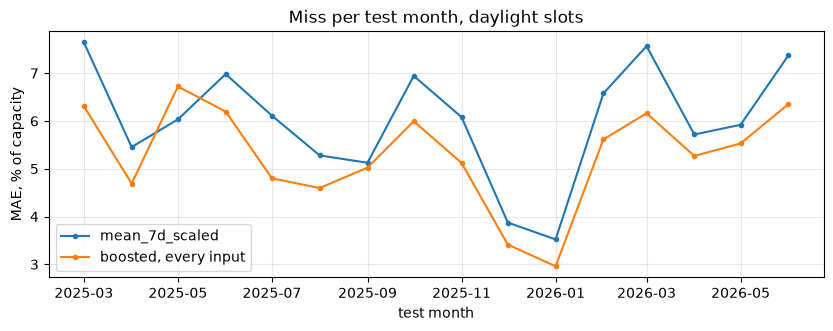

fold,2025-03-01,2025-04-01,2025-05-01,2025-06-01,2025-07-01,2025-08-01,2025-09-01,2025-10-01,2025-11-01,2025-12-01,2026-01-01,2026-02-01,2026-03-01,2026-04-01,2026-05-01,2026-06-01
mean_7d_scaled,0.0765,0.0545,0.0603,0.0698,0.0611,0.0528,0.0513,0.0694,0.0608,0.0387,0.0352,0.0658,0.0757,0.0572,0.0592,0.0737
"boosted, every input",0.0631,0.0469,0.0672,0.0620,0.0480,0.0460,0.0502,0.0599,0.0512,0.0341,0.0296,0.0561,0.0616,0.0527,0.0553,0.0635
boosted better by,0.0134,0.0076,-0.0069,0.0078,0.0131,0.0068,0.0010,0.0095,0.0096,0.0046,0.0056,0.0096,0.0140,0.0045,0.0039,0.0102


In [7]:
def by_month(said: pd.DataFrame) -> pd.Series:
    return metrics(outcomes(said))[0].set_index("fold")["mae_share"]


months = pd.DataFrame({name: by_month(said) for name, said in candidates.items()})
months["boosted better by"] = months["mean_7d_scaled"] - months["boosted, every input"]
print(
    "months in which the boosted model misses by less:",
    int((months["boosted better by"] > 0).sum()),
    "of",
    len(months),
)
fig, ax = plt.subplots(figsize=(10, 3.2))
(months[["mean_7d_scaled", "boosted, every input"]] * 100).plot(ax=ax, marker="o", ms=3)
ax.set_ylabel("MAE, % of capacity")
ax.set_xlabel("test month")
ax.grid(alpha=0.3)
ax.set_title("Miss per test month, daylight slots")
plt.show()
months.T

**What it shows.** **Observed:**

- **All of the gain is on clear days:** 3.27% against 4.99%
- **On mixed and cloudy days it only matches the rule:** 6.21% against 6.29%, and 7.27% against 7.34%
- **On cloudy days it forecasts 5 points too high, as the rule does,** and its range holds 61%
- **Better in 15 of 16 months.** May 2025 is the exception, by 0.69 points

**Learned → design:** the assumption holds: with plain settings the model beats the strongest baseline. What it adds is the shape of a clear day, which the rule gets from a week's average. What neither has is a better call of a cloudy day than the forecast itself gives.

## 4. Which inputs earn their place

### 4.1 Leaving each one out

**Step.** The model is trained eleven more times, each time without one input. `against` is the change in the miss from the model with every input (negative is better), and `months better` counts the test months in which the smaller set misses by less.

In [8]:
SAID = {ALL: said_all}  # every set of inputs tried, with its forecasts


def tried(inputs: tuple[str, ...]) -> pd.DataFrame:
    if inputs not in SAID:
        SAID[inputs] = backtest(inputs)[0]
    return SAID[inputs]


def compare(variants: dict[str, tuple[str, ...]], against: tuple[str, ...] = ALL) -> pd.DataFrame:
    """Each set of inputs scored on the test months, beside the set it is measured against:
    overall, by sky, and in how many of the 16 months it misses by less."""
    reference = by_month(tried(against))
    rows = {}
    for name, inputs in variants.items():  # a backtest each
        said = tried(inputs)
        overall, sky = score(said), by_sky(said)["mae_share"]
        rows[name] = {
            "inputs": len(inputs),
            "mae_share": overall["mae_share"],
            "against": overall["mae_share"]
            - reference.pipe(lambda _: score(tried(against))["mae_share"]),
            "months better": int((by_month(said) < reference).sum()),
            "clear": sky["clear"],
            "mixed": sky["mixed"],
            "cloudy": sky["cloudy"],
            "coverage": overall["coverage"],
        }
    return pd.DataFrame(rows).T


without = {f"without {name}": tuple(i for i in ALL if i != name) for name in ALL}
one_out = compare({"every input": ALL} | without)
one_out.sort_values("mae_share")

,inputs,mae_share,against,months better,clear,mixed,cloudy,coverage
without day_of_year,10.0000,0.0520,-0.0016,13.0000,0.0321,0.0590,0.0718,0.7230
without forecast_ghi_w_m2,10.0000,0.0535,-0.0001,8.0000,0.0330,0.0615,0.0727,0.7051
without forecast_direct_w_m2,10.0000,0.0535,-0.0000,6.0000,0.0333,0.0608,0.0735,0.7012
every input,11.0000,0.0536,0.0000,0.0000,0.0327,0.0621,0.0727,0.7128
without forecast_diffuse_w_m2,10.0000,0.0536,0.0000,8.0000,0.0332,0.0612,0.0733,0.7122
without clear_sky_share,10.0000,0.0537,0.0001,7.0000,0.0336,0.0615,0.0724,0.7048
without forecast_ghi_mean_7d_w_m2,10.0000,0.0537,0.0001,6.0000,0.0330,0.0619,0.0729,0.7133
without forecast_temperature_c,10.0000,0.0538,0.0002,4.0000,0.0324,0.0620,0.0742,0.7028
without mean_7d_share,10.0000,0.0538,0.0002,7.0000,0.0327,0.0621,0.0735,0.7086
without forecast_cloud_cover_pct,10.0000,0.0541,0.0005,7.0000,0.0326,0.0621,0.0747,0.7092


**What it shows.** **Observed:**

- **Without the day of the year the model is better:** 5.20%, in 13 of 16 months
- **Without the half hour it is worse:** 5.48%, in 14 of 16 months
- **For the other nine, leaving one out changes the miss by 0.05 points at most,** total radiation among them

**This reading misleads.** Taken at its word, the table says the model can do without the forecast's total radiation, or without any one of eight other inputs. It can't do without all of them. Several inputs say nearly the same thing (total radiation is close to direct plus diffuse; the week's output follows the week's forecast), and when one is left out another takes its place. Leaving one out measures what an input adds beyond all the others, not what it is worth. The next two steps ask in two other ways.

### 4.2 Leaving out a group

**Step.** Starting from the ten inputs without the day of the year, inputs that say similar things are left out together.

In [9]:
def less(inputs: tuple[str, ...], *dropped: str) -> tuple[str, ...]:
    return tuple(name for name in inputs if name not in dropped)


TEN = less(ALL, "day_of_year")
RADIATION = ("forecast_ghi_w_m2", "forecast_direct_w_m2", "forecast_diffuse_w_m2")
OTHER_WEATHER = ("forecast_cloud_cover_pct", "forecast_temperature_c")
PAST = ("mean_7d_share", "d2_share", "forecast_ghi_mean_7d_w_m2")
groups = compare(
    {
        "ten: all but the day of the year": TEN,
        "without direct and diffuse (total radiation kept)": less(TEN, *RADIATION[1:]),
        "without total radiation (direct and diffuse kept)": less(TEN, RADIATION[0]),
        "without any radiation of the day": less(TEN, *RADIATION),
        "without cloud cover and temperature": less(TEN, *OTHER_WEATHER),
        "without anything forecast for the day": less(TEN, *RADIATION, *OTHER_WEATHER),
        "without the past (the week's output and forecast, two days back)": less(TEN, *PAST),
        "without the sun's place (clear sky, half hour)": less(TEN, "clear_sky_share", "half_hour"),
    },
    against=TEN,
)
groups

,inputs,mae_share,against,months better,clear,mixed,cloudy,coverage
ten: all but the day of the year,10.0000,0.0520,0.0000,0.0000,0.0321,0.0590,0.0718,0.7230
without direct and diffuse (total radiation kept),8.0000,0.0529,0.0009,4.0000,0.0329,0.0595,0.0734,0.7270
without total radiation (direct and diffuse kept),9.0000,0.0524,0.0004,6.0000,0.0321,0.0598,0.0721,0.7217
without any radiation of the day,7.0000,0.0598,0.0078,1.0000,0.0376,0.0661,0.0840,0.7228
without cloud cover and temperature,8.0000,0.0543,0.0023,4.0000,0.0322,0.0589,0.0805,0.7299
without anything forecast for the day,5.0000,0.1013,0.0493,0.0000,0.0786,0.0624,0.1893,0.7426
"without the past (the week's output and forecast, two days back)",7.0000,0.0527,0.0007,6.0000,0.0314,0.0603,0.0737,0.7412
"without the sun's place (clear sky, half hour)",8.0000,0.0544,0.0024,0.0000,0.0383,0.0600,0.0707,0.7178


**What it shows.** **Observed**, against 5.20% with the ten:

| Left out | Miss | What it costs |
| --- | --- | --- |
| Everything forecast for the day | 10.13% | 4.9 points: the model is back at the seven-day mean's level, and at 18.9% on cloudy days |
| All three radiation columns | 5.98% | 0.8 points, in 15 of 16 months |
| The sun's place: clear sky and the half hour | 5.44% | 0.24 points, in every month, all of it on clear days |
| Cloud cover and temperature | 5.43% | 0.23 points, nearly all of it on cloudy days (8.05% against 7.18%) |
| Direct and diffuse, total kept | 5.29% | 0.09 points |
| Total radiation, direct and diffuse kept | 5.24% | 0.04 points |
| The past: the week's output, the week's forecast, two days back | 5.27% | 0.07 points, in 10 of 16 months |

**Learned → design:**

- **The forecast for the day is the model.** Radiation is needed in some form; which of its three columns matters little
- **Cloud cover and temperature earn their place on cloudy days,** where radiation alone says least
- **The past week adds little once the forecast is there.** The rule needs the seven-day mean; the model, given the forecast and the sun's place, nearly doesn't

### 4.3 Building the set up

**Step.** The opposite direction: start with no input, and at each step add the one that lowers the miss most. Each step is a backtest per input still out, 66 in all.

In [10]:
def build_up(candidates: tuple[str, ...]) -> pd.DataFrame:
    """Start from no input; at each step add the one that lowers the miss most, and say what it
    gained. Every step is a backtest per input still out."""
    chosen, steps = (), []
    while len(chosen) < len(candidates):  # each step depends on the last
        left = [name for name in candidates if name not in chosen]
        misses = pd.Series({name: score(tried((*chosen, name)))["mae_share"] for name in left})
        best = misses.idxmin()
        chosen = (*chosen, best)
        said = tried(chosen)
        steps.append(
            {
                "added": best,
                "mae_share": misses[best],
                "runner-up": misses.drop(best).idxmin() if len(left) > 1 else "",
                "runner-up's": misses.drop(best).min() if len(left) > 1 else np.nan,
                "coverage": score(said)["coverage"],
                **by_sky(said)["mae_share"][["clear", "mixed", "cloudy"]],
            }
        )
    out = pd.DataFrame(steps)
    out.insert(2, "gained", -out["mae_share"].diff())
    return out


started = time.time()
steps = build_up(ALL)
print(f"{len(SAID)} sets of inputs tried so far; this cell took {time.time() - started:.0f} s")
steps

85 sets of inputs tried so far; this cell took 179 s


,added,mae_share,gained,runner-up,runner-up's,coverage,clear,mixed,cloudy
0,forecast_ghi_w_m2,0.0687,NaN,forecast_direct_w_m2,0.0753,0.7829,0.0542,0.0709,0.0872
1,half_hour,0.0582,0.0105,mean_7d_share,0.0623,0.7726,0.0307,0.0622,0.0933
2,forecast_cloud_cover_pct,0.0553,0.0029,forecast_diffuse_w_m2,0.0561,0.7730,0.0322,0.0601,0.0828
3,forecast_temperature_c,0.0535,0.0018,mean_7d_share,0.0547,0.7607,0.0319,0.0605,0.0757
4,forecast_direct_w_m2,0.0528,0.0007,forecast_diffuse_w_m2,0.0532,0.7563,0.0315,0.0604,0.0738
5,mean_7d_share,0.0525,0.0003,d2_share,0.0525,0.7388,0.0325,0.0592,0.0727
6,clear_sky_share,0.0524,0.0000,d2_share,0.0526,0.7373,0.0320,0.0593,0.0731
7,forecast_ghi_mean_7d_w_m2,0.0523,0.0001,d2_share,0.0524,0.7357,0.0327,0.0588,0.0724
8,forecast_diffuse_w_m2,0.0521,0.0002,d2_share,0.0522,0.7336,0.0322,0.0587,0.0726
9,d2_share,0.0521,0.0001,day_of_year,0.0540,0.7222,0.0319,0.0593,0.0719


**What it shows.** **Observed:**

- **Two inputs already beat the bar:** the forecast's total radiation alone gives 6.87%, and with the half hour 5.82%
- **Cloud cover, temperature and direct radiation bring it to 5.28%**
- **The next five add 0.07 points between them:** the week's output, clear sky, the week's forecast, diffuse radiation, two days back, none more than 0.03
- **The day of the year, added last, costs 0.16 points**
- **The range narrows as inputs are added:** it holds 78% with one input, 73% with nine, 71% with eleven

**Learned → design:** five inputs carry the model. The order agrees with section 4.2 and not with 4.1: total radiation, which could be left out of eleven at no cost, is the first input chosen.

### 4.4 Why the day of the year costs

**Step.** Its cost per test month, beside how much history each month's model had, and its weight in the trees at the first and the last training.

In [11]:
# What the day of the year costs, month by month, and whether more history makes it cost less
cost = (by_month(tried(ALL)) - by_month(tried(TEN))).rename("cost of the day of the year")
history = fits_all.set_index("fold")["training_slots"].rename("daylight slots trained on")
early, late = cost.iloc[:8].mean(), cost.iloc[8:].mean()
print(
    f"months in which it costs: {int((cost > 0).sum())} of {len(cost)}; "
    f"mean cost in the first 8 test months: {early:.4f}; in the last 8: {late:.4f}"
)
weight = fits_all["gain_share/day_of_year"]
print(
    "its share of the middle model's gain, first and last training:",
    f"{weight.iloc[0]:.3f}, {weight.iloc[-1]:.3f}",
)
pd.concat([cost, history], axis=1).T

months in which it costs: 13 of 16; mean cost in the first 8 test months: 0.0022; in the last 8: 0.0007
its share of the middle model's gain, first and last training: 0.064, 0.032


fold,2025-03-01,2025-04-01,2025-05-01,2025-06-01,2025-07-01,2025-08-01,2025-09-01,2025-10-01,2025-11-01,2025-12-01,2026-01-01,2026-02-01,2026-03-01,2026-04-01,2026-05-01,2026-06-01
cost of the day of the year,0.0000,-0.0001,0.0001,0.0035,0.0092,0.0018,0.0014,0.0016,0.0013,0.0008,0.0004,-0.0012,0.0013,-0.0007,0.0037,0.0001
daylight slots trained on,"9,536.0000","10,302.0000","11,118.0000","12,019.0000","12,928.0000","13,838.0000","14,706.0000","15,486.0000","16,215.0000","16,865.0000","17,498.0000","18,156.0000","18,789.0000","19,555.0000","20,371.0000","21,272.0000"


**What it shows.** **Observed:**

- **It costs in 13 of 16 months,** 0.92 points in July 2025
- **The cost falls as history grows:** 0.22 points a month on average over the first eight test months, 0.07 over the last eight
- **So does its weight in the trees:** 6.4% of the middle model's gain at the first training, 3.2% at the last

**Learned → design:** the first model has seen each date once, and the last one twice or three times. With so few years, a tree that splits on the date can tie it to the weather that date happened to have. This is consistent with what is seen (a cost that shrinks with more years), not proven by it. The season the model needs it already has from clear-sky output and temperature. **The day of the year is left out.** The plan said clear-sky output needs the hour and the day of the year beside it; the hour, yes.

### 4.5 Nine, ten or five

**Step.** Three sets are left to choose from: the ten without the day of the year, the nine that also leave out two days back, and the first five of section 4.3. The nine are also trained in the order section 4.3 added them, to see what the order of the inputs does.

In [12]:
FIVE = tuple(steps["added"].iloc[:5])
NINE = less(TEN, "d2_share")
print("five:", FIVE)
choice = compare(
    {
        "ten: all but the day of the year": TEN,
        "nine: those without two days back": NINE,
        "the same nine, in the order they were added": tuple(steps["added"].iloc[:9]),
        "five: the first five added": FIVE,
    },
    against=TEN,
)
versus = by_month(tried(NINE))
print(
    "months of 16 in which nine misses by less than ten:",
    int((versus < by_month(tried(TEN))).sum()),
    "| in which five misses by less than nine:",
    int((by_month(tried(FIVE)) < versus).sum()),
    "| largest monthly difference between five and nine:",
    f"{(by_month(tried(FIVE)) - versus).abs().max():.4f}",
)
choice

five: ('forecast_ghi_w_m2', 'half_hour', 'forecast_cloud_cover_pct', 'forecast_temperature_c', 'forecast_direct_w_m2')


months of 16 in which nine misses by less than ten: 9 | in which five misses by less than nine: 5 | largest monthly difference between five and nine: 0.0035


,inputs,mae_share,against,months better,clear,mixed,cloudy,coverage
ten: all but the day of the year,10.0000,0.0520,0.0000,0.0000,0.0321,0.0590,0.0718,0.7230
nine: those without two days back,9.0000,0.0521,0.0001,9.0000,0.0322,0.0585,0.0726,0.7311
"the same nine, in the order they were added",9.0000,0.0521,0.0001,8.0000,0.0322,0.0587,0.0726,0.7336
five: the first five added,5.0000,0.0528,0.0008,7.0000,0.0315,0.0604,0.0738,0.7563


**What it shows.** **Observed:**

- **Ten and nine can't be told apart:** 5.20% and 5.21%, the nine better in 9 months of 16
- **Five is 0.07 points behind nine** (5.28%), behind in 11 months of 16, never by more than 0.35 points. Its range is the better one: 76% against 73%
- **The order of the inputs moves the result in the fourth decimal:** the same nine in another order give 5.21% and differ in single months

**Learned → design:**

- **Two days back is left out.** It adds a hundredth of a point, and it would make every forecast depend on one more day's actuals being known in time
- **The model keeps the nine.** The four beyond the five add little each, but together they help in 11 months of 16, they are already built in DWS, and the week's output is the only input that knows the state of the fleet rather than of the sky. Five would be the choice if the range mattered more than the middle forecast
- **The inputs' order is part of the model:** it is fixed in the code, since another order is another model file

## 5. The other target the plan names

**Step.** The plan has the model predict output as a share of capacity, and says: "Whether dividing by clear-sky output does better is tried in the first backtest." It is tried here, once, with the nine inputs. The target becomes output over clear-sky output, on the slots lit enough to divide by (clear sky at 5% of capacity or more: 11,175 of the 12,652 test slots). Dimmer slots get the forecast of the model that learned shares of capacity.

In [13]:
class OverClearSky:
    """The same three models with another target: output over clear-sky output, on the slots lit
    enough to divide by (clear sky at 5% of capacity or more). Dimmer slots get the forecast of
    the model that learned shares of capacity."""

    def __init__(self, rows: pd.DataFrame, inputs: tuple[str, ...]):
        self.inputs, self.shares = inputs, train_boosted(rows, inputs)
        known = rows[self.lit(rows) & rows["is_daylight"].astype(bool) & rows["label_mw"].notna()]
        ratio = (known["label_mw"] / known["clear_sky_mw"]).astype(float)
        given = boosted_inputs(known, inputs)
        self.boosters = [
            lightgbm.train(
                BOOSTED_SETTINGS | {"alpha": alpha}, lightgbm.Dataset(given, ratio), ROUNDS
            )
            for alpha in ALPHAS.values()
        ]
        self.summary = {"training_slots": float(len(known)), "largest_ratio": float(ratio.max())}

    @staticmethod
    def lit(rows: pd.DataFrame) -> pd.Series:
        return rows["clear_sky_mw"] >= 0.05 * rows["capacity_mw"]

    def predict(self, features: pd.DataFrame) -> pd.DataFrame:
        given = boosted_inputs(features, self.inputs)
        named = zip(QUANTILES, self.boosters, strict=True)
        ratios = pd.DataFrame({name: b.predict(given) for name, b in named}, index=features.index)
        said = ratios.mul(features["clear_sky_mw"], axis=0).clip(lower=0.0)
        return said.where(self.lit(features), self.shares.predict(features))

    def dump(self) -> str:
        return ""


said_ratio, fits_ratio = (lambda out: (out[0], pd.DataFrame(out[1]).drop(columns="file")))(
    train_by_month(lambda rows: OverClearSky(rows, NINE), known, test)
)
lit_test = OverClearSky.lit(test) & test["is_daylight"].astype(bool)
scored_slots = int(test["is_daylight"].sum())
print(
    f"daylight test slots lit enough to divide by: {int(lit_test.sum()):,} of {scored_slots:,}; "
    f"largest ratio trained on: {fits_ratio['largest_ratio'].max():.2f}"
)
targets = pd.DataFrame(
    {"share of capacity": score(tried(NINE)), "over clear sky": score(said_ratio)}
).T
targets["months better"] = [0, int((by_month(said_ratio) < by_month(tried(NINE))).sum())]
targets = targets.join(
    pd.DataFrame(
        {
            "share of capacity": by_sky(tried(NINE))["mae_share"],
            "over clear sky": by_sky(said_ratio)["mae_share"],
        }
    ).T[["clear", "mixed", "cloudy"]]
)
targets

daylight test slots lit enough to divide by: 11,175 of 12,652; largest ratio trained on: 1.24


,slots,mae_share,bias_share,mae_mw,coverage,pinball_share,months better,clear,mixed,cloudy
share of capacity,"12,652.0000",0.0521,0.0081,"1,057.1442",0.7311,0.0167,0,0.0322,0.0585,0.0726
over clear sky,"12,652.0000",0.0531,0.0111,"1,077.7769",0.7053,0.0172,7,0.0314,0.0599,0.0759


**What it shows.** **Observed:**

- **It does slightly worse:** 5.31% against 5.21%, better in 7 months of 16
- **Better on clear days** (3.14% against 3.22%), **worse on cloudy ones** (7.59% against 7.26%)
- **Its range is narrower still:** it holds 71%

**Learned → design:** the target stays output over capacity. Dividing by clear sky is exact where the sky is clear and magnifies errors where output is small against it, which is where the model is weakest. It also needs a second model for the slots too dim to divide by.

## 6. The nine, by kind of day

**Step.** The chosen set against the bar, overall and by the groups results are read by.

In [14]:
said_nine, fits_nine = backtest(NINE)
table.loc["boosted, nine inputs"] = score(said_nine)
scaled = scaled_mean(test).to_frame("predicted_mw")
kinds = pd.concat(
    {
        name: by_group(outcomes(said)).set_index(["grouping", "group"])
        for name, said in {"mean_7d_scaled": scaled, "boosted, nine": said_nine}.items()
    },
    axis=1,
)
width = ((said_nine["p90_mw"] - said_nine["p10_mw"]) / test["capacity_mw"])[
    test["is_daylight"].astype(bool)
]
skill = (
    1 - table.loc["boosted, nine inputs", "mae_share"] / table.loc["mean_7d_scaled", "mae_share"]
)
won = int((by_month(said_nine) < by_month(scaled)).sum())
print(
    f"skill against the scaled seven-day mean: {skill:.3f}; "
    f"months in which nine misses by less: {won} of 16; "
    f"the range's mean width in daylight: {width.mean():.3f} of capacity"
)
display(table)
kinds.loc[:, pd.IndexSlice[:, ["days", "mae_share", "bias_share", "coverage"]]].dropna(
    axis=1, how="all"
)

skill against the scaled seven-day mean: 0.141; months in which nine misses by less: 15 of 16; the range's mean width in daylight: 0.160 of capacity


,slots,mae_share,bias_share,mae_mw,coverage,pinball_share
mean_7d,"12,652.0000",0.1052,0.0018,"2,132.8376",NaN,NaN
mean_7d_scaled,"12,652.0000",0.0606,-0.0000,"1,230.5934",NaN,NaN
mean_7d_range,"12,652.0000",0.1036,0.0168,"2,101.8319",0.7874,0.0327
"boosted, every input","12,652.0000",0.0536,0.0068,"1,087.3967",0.7128,0.0172
"boosted, nine inputs","12,652.0000",0.0521,0.0081,"1,057.1442",0.7311,0.0167


mean_7d_scaled boosted, nine mean_7d_scaled boosted, nine mean_7d_scaled boosted, nine         
                              days          days      mae_share     mae_share     bias_share    bias_share coverage
grouping  group                                                                                                    
curtailed curtailed             20            20         0.0536        0.0378        -0.0267       -0.0146   0.7934
          normal               467           467         0.0610        0.0527         0.0012        0.0091   0.7283
season    autumn                91            91         0.0603        0.0527         0.0018        0.0105   0.7421
          spring               184           184         0.0635        0.0567         0.0031        0.0120   0.7153
          summer               122           122         0.0645        0.0522        -0.0045        0.0019   0.7496
          winter                90            90         0.0464        0.0393        -0.0017        0.0068   0.7251
sky       clear                190           190         0.0499        0.0322        -0.0292       -0.0201   0.7383
          cloudy               123           123         0.0734        0.0726         0.0484        0.0539   0.6357
          mixed                174           174         0.0629        0.0585        -0.0037        0.0052   0.7917

**What it shows.** **Observed:**

- **5.21% of capacity against 6.06%: a skill of 0.14,** better in 15 months of 16. In MW, 1,057 against 1,231
- **Clear days: 3.2% against 5.0%.** Mixed: 5.9% against 6.3%. **Cloudy: 7.3% against 7.3%**
- **Every season is better,** summer the most (5.22% against 6.45%). The 20 curtailed days too: 3.8% against 5.4%
- **The range holds 73%,** 79% on mixed days and curtailed days, and 64% on cloudy days. It is 16% of capacity wide on average
- **A bias of 0.8 points too high overall,** from cloudy days: 5.4 points too high there, 2.0 too low on clear days

The bias by sky is partly how the groups are made: a day is called cloudy because its output was low, so any forecast made the day before looks too high on it. The rule shows the same pattern.

**Step.** How much each input weighs in the trees, beside what leaving it out of the nine costs.

In [15]:
# How much each input weighed in the middle model's trees, in the first training and the last,
# beside what leaving it out of the nine costs
gains = (
    fits_nine.set_index("fold").filter(like="gain_share/").rename(columns=lambda c: c.split("/")[1])
)
weights = gains.iloc[[0, -1]].T.set_axis(
    ["weight, first training", "weight, last training"], axis=1
)
weights["cost of leaving it out"] = (
    pd.Series({name: score(tried(less(NINE, name)))["mae_share"] for name in NINE})
    - score(said_nine)["mae_share"]
)
weights.sort_values("weight, last training", ascending=False)

,"weight, first training","weight, last training",cost of leaving it out
forecast_ghi_w_m2,0.4464,0.4861,0.0003
clear_sky_share,0.1926,0.1807,0.0000
mean_7d_share,0.1219,0.1530,0.0006
half_hour,0.0537,0.0504,0.0018
forecast_direct_w_m2,0.0411,0.0454,0.0008
forecast_cloud_cover_pct,0.0328,0.0286,0.0002
forecast_temperature_c,0.0358,0.0280,0.0015
forecast_ghi_mean_7d_w_m2,0.0307,0.0191,0.0004
forecast_diffuse_w_m2,0.0449,0.0086,0.0003


In [16]:
from jtf.ml.models import KEPT_INPUTS

print("the model's code keeps the nine chosen here, in this order:", KEPT_INPUTS == NINE)
print(f"{len(SAID)} sets of inputs were tried in this notebook")

the model's code keeps the nine chosen here, in this order: True
95 sets of inputs were tried in this notebook


**What it shows.** **Observed:** clear-sky output carries 18% of the middle model's gain and the week's output 15%, second and third after total radiation (49%). Leaving either out costs 0.00 and 0.06 points. The half hour carries 5% and costs 0.18.

**Learned → design:** an input's weight in the trees says how often it was the handiest split, not what the model would lose without it. Inputs are judged by backtests with and without them, in groups and built up, as in section 4. The weights are logged with every training for what they are.

## What this exploration made known

| We assumed | We found | So |
| --- | --- | --- |
| A training repeats exactly on one machine | It does, to the byte, with any number of threads and any seed: nothing is drawn at random at default settings (section 1) | A reproduce trains again and compares. One thread and a seed stay fixed, because the thread count is written into the model's file |
| The model given every input beats the scaled seven-day mean | 5.36% of capacity against 6.06%, in 15 of 16 months; all of the gain on clear days (section 3) | The plan's criterion can be met with plain settings |
| An input's worth is read by leaving it out | No: nine of eleven inputs can each be left out for 0.05 points or less, total radiation among them, yet without the day's forecast the miss doubles. Inputs that say the same thing cover for each other (sections 4.1 to 4.3) | Inputs are judged in groups and by building the set up, not one at a time and not by their weight in the trees |
| The hour and the day of the year belong beside clear-sky output (the plan) | The half hour, yes. The day of the year costs in 13 of 16 months, less as history grows (section 4.4) | **The day of the year is left out** |
| The same slot two days back is an input (the plan) | It adds 0.01 points (section 4.5) | **Left out:** one less day of actuals for a forecast to depend on |
| Dividing by clear-sky output may be the better target (the plan) | 5.31% against 5.21%: better on clear days, worse on cloudy ones (section 5) | **The target stays output over capacity** |
| The range holds somewhat under 80% | 73%, and 64% on cloudy days; it narrows as inputs are added (sections 4.3, 6) | Reported as it is. Widening it is tuning, after phase 1 |
| (Not asked beforehand) Whether this notebook's scores are the pipeline's | They agree with three recorded runs to 5 × 10⁻¹² (section 2) | The comparisons here stand for what recorded runs would show |
| (Not asked beforehand) Where the model still fails | Cloudy days: 7.3%, no better than the rule, and 5 points too high (section 6) | What is left there is the forecast's own error. A fresher forecast is the lever, not more inputs from this one |

**The model keeps nine inputs:** the week's output, clear-sky output, the forecast's total, direct and diffuse radiation, its cloud cover and temperature, its total radiation over the past week, and the half hour. With them it misses by 5.21% of capacity on March 2025 to June 2026, a skill of 0.14 against the strongest baseline.

## Still open

| What | Why it can't be known yet | When |
| --- | --- | --- |
| Whether another machine trains the same file | One machine was used here; LightGBM promises the same result for the same version and binary only | When CI runs the model's tests, which record a file's hash |
| Whether the held-back months agree | July to October 2026 are looked at once | The model's recorded backtest, after it is registered |
| Whether the day of the year stops costing with more years | Two and a half years of history | A later backtest, once a third full year is in |
| What a one-day-old forecast does for cloudy days | The history holds two-day-old forecasts ([notebook 10](10_what_the_forecast_knows.ipynb), Still open) | After some weeks of live capture |

## Where the sources and the data disagree

| Where | Says | We found | Handled by |
| --- | --- | --- | --- |
| [Phase-1 plan](../docs/phase1/README.md#model-and-evaluation), Inputs | "hour and day of year, which clear-sky output needs beside it" | The day of the year makes the model worse (section 4.4) | Left out of the model; the plan is changed |
| The same | "D−2 same-slot output" among the inputs | It adds nothing measurable (section 4.5) | Left out of the model; the plan is changed. It stays the persistence baseline |
| The same, Target | "Whether dividing by clear-sky output does better is tried in the first backtest" | Tried: it does slightly worse (section 5) | The plan records the result |
| LightGBM's parameter reference, `seed` and `deterministic` | Different seeds are expected to give different results | With default settings the seed changes nothing: no row or input is sampled (section 1) | No conflict: the reference describes what a seed can do, not what it does at these settings |

## Sources

| Page | Supports |
| --- | --- |
| [LightGBM, Parameters](https://lightgbm.readthedocs.io/en/latest/Parameters.html#deterministic) | What `deterministic` promises and where it stops; that it wants `force_row_wise` or `force_col_wise` beside it |
| [Notebook 10](10_what_the_forecast_knows.ipynb), section 4 | The bar: the scaled seven-day mean at 6.06% of capacity |
| [Notebook 09](09_output_against_clear_sky.ipynb), section 4 | Why power is given to a tree as a share of capacity |
| `jtf/src/jtf/ml/models.py`, `jtf/src/jtf/ml/replay.py` | The model's training and the month-by-month backtest used here |
| `warehouse/dbt/models/ads/ads_ml_outcome_solar.sql` | How a recorded run's forecasts are scored |